In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import rioxarray as rxr
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt

In [2]:
dem = rxr.open_rasterio("data_processed/dem_1km_res.tif").squeeze()
dem = dem.where(dem != -32768)   # crs projection of master grid our dem is 4326

slope = rxr.open_rasterio("data_processed/slope.tif").squeeze() #crs projection is 3857

aspect = rxr.open_rasterio("data_processed/aspect.tif").squeeze() #crs projection is 3857

tern_rgd = rxr.open_rasterio("data_processed/tri.tif").squeeze() # terrain ruggedness crs projection is 3857

temp = rxr.open_rasterio("data_processed/breeding_temp_1km.tif").squeeze() # crs projection is 4326


In [3]:
# We reproject required rasters to match our DEM raster
slope = slope.rio.reproject_match(dem)
aspect = aspect.rio.reproject_match(dem)
aspect

<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan, 211.32869, 208.41266, ...,  88.8876 ,       nan,
              nan],
       [      nan, 219.80557, 237.65256, ..., 117.52522,       nan,
              nan],
       ...,
       [      nan, 356.63354, 298.61047, ...,  -1.     ,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      aspect
    _FillValue:     -32768.0

In [4]:
# Now the dimensions are different so we reproject to match our master grid DEM model
ndvi_alps = rxr.open_rasterio("data_processed/NDVI_Swiss_Alps.tif").squeeze()

print("Original Seninel 2A Shape:",ndvi_alps.shape)

ndvi_alps = ndvi_alps.rio.reproject_match(dem)

print("New Shape:", ndvi_alps.shape)

Original Seninel 2A Shape: (339, 669)
New Shape: (301, 801)


In [5]:
data_tot = pd.read_csv('ptarmigan_sdm_dataset.csv')
data_tot

,species,locality,decimalLatitude,decimalLongitude,year,basisOfRecord,geometry,elev,slope,aspect,temp,ndvi_alps,label
0,Lagopus muta,Wallis (VS),46.028279,7.455767,2025.0,HUMAN_OBSERVATION,POINT (7.455767 46.028279),2930.0,10.773954,144.639206,3.118364,0.193581,1
1,Lagopus muta,Wallis (VS),46.028358,7.455630,2025.0,HUMAN_OBSERVATION,POINT (7.45563 46.028358),2930.0,10.773954,144.639206,3.118364,0.193581,1
2,Lagopus muta,Wallis (VS),46.579033,8.390598,2025.0,HUMAN_OBSERVATION,POINT (8.390598 46.579033),2324.0,12.428118,241.524979,6.849370,0.627609,1
3,Lagopus muta,Zernez (Gemeinde),46.725304,9.970130,2025.0,HUMAN_OBSERVATION,POINT (9.97013 46.725304),2622.0,11.163825,99.643227,6.997581,0.338768,1
4,Lagopus muta,Safiental-oberes,46.621277,9.256653,2026.0,HUMAN_OBSERVATION,POINT (9.256653 46.621277),2216.0,16.436100,90.163582,8.193323,0.640389,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2314,NaN,NaN,NaN,NaN,NaN,NaN,POINT (5.146912778923087 45.90880335956503),295.0,0.493671,215.049377,19.119356,0.402490,0
2315,NaN,NaN,NaN,NaN,NaN,NaN,POINT (8.424670903005094 46.86881977327097),1800.0,24.226080,7.637166,11.974321,0.715982,0
2316,NaN,NaN,NaN,NaN,NaN,NaN,POINT (7.903619376040676 47.911279119219245),1183.0,3.783798,350.192810,15.549364,0.783397,0
2317,NaN,NaN,NaN,NaN,NaN,NaN,POINT (6.321486327140597 45.657855633615455),459.0,4.651557,139.197662,15.095263,0.688531,0


In [6]:
# We keep only relevant data now.. and move ot model building in next ntbk
data_alp = data_tot[["geometry","elev","slope","aspect","temp","ndvi_alps","label"]]
data_alp

,geometry,elev,slope,aspect,temp,ndvi_alps,label
0,POINT (7.455767 46.028279),2930.0,10.773954,144.639206,3.118364,0.193581,1
1,POINT (7.45563 46.028358),2930.0,10.773954,144.639206,3.118364,0.193581,1
2,POINT (8.390598 46.579033),2324.0,12.428118,241.524979,6.849370,0.627609,1
3,POINT (9.97013 46.725304),2622.0,11.163825,99.643227,6.997581,0.338768,1
4,POINT (9.256653 46.621277),2216.0,16.436100,90.163582,8.193323,0.640389,1
...,...,...,...,...,...,...,...
2314,POINT (5.146912778923087 45.90880335956503),295.0,0.493671,215.049377,19.119356,0.402490,0
2315,POINT (8.424670903005094 46.86881977327097),1800.0,24.226080,7.637166,11.974321,0.715982,0
2316,POINT (7.903619376040676 47.911279119219245),1183.0,3.783798,350.192810,15.549364,0.783397,0
2317,POINT (6.321486327140597 45.657855633615455),459.0,4.651557,139.197662,15.095263,0.688531,0


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score


X = data_alp[["elev","slope","aspect","temp","ndvi_alps"]]
y = data_alp["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


rnfor = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)

rnfor.fit(X_train, y_train)
rnfor.fit(X, y)

RandomForestClassifier(max_depth=10, random_state=42)

In [20]:
print(rnfor.feature_importances_)

[0.26650839 0.16503331 0.11671526 0.32903526 0.12270778]


In [21]:
y_pred_rf = rnfor.predict_proba(X)[:,1]

auc_rf = roc_auc_score(y, y_pred_rf)

print("RF AUC:", auc_rf)

RF AUC: 0.9999983950670782


In [23]:
y_pred_rf = rnfor.predict_proba(X_test)[:,1]
auc_rf = roc_auc_score(y_test, y_pred_rf)

print("RF AUC (test):", auc_rf)

RF AUC (test): 0.9999955892731122


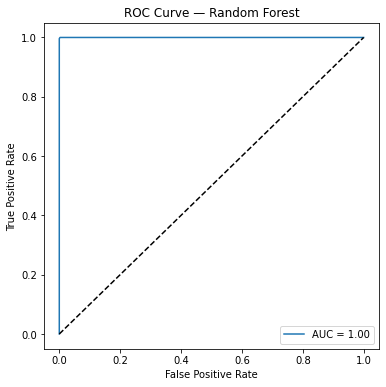

In [25]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)

plt.figure(figsize=(6,6))
plt.plot(fpr_rf, tpr_rf, label=f"AUC = {auc_rf:.2f}")

plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Random Forest")
plt.legend()

plt.show()

In [9]:
# Stack the data points

stack = np.stack([dem, slope, aspect, temp, ndvi_alps], axis=-1)

flat = stack.reshape(-1, 5)

mask = ~np.isnan(flat).any(axis=1)

pred_rf = np.zeros(flat.shape[0])

pred_rf[mask] = rnfor.predict_proba(flat[mask])[:,1]

prob_map_rf = pred_rf.reshape(dem.shape)

C:\Users\91702\anaconda3\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


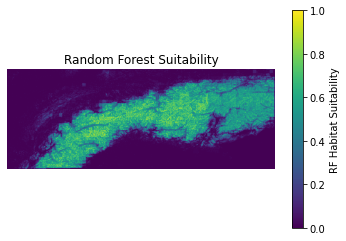

In [10]:
plt.imshow(prob_map_rf, cmap="viridis")
plt.colorbar(label="RF Habitat Suitability")
plt.title("Random Forest Suitability")
plt.axis("off")
plt.show()

### Now let's move to Future Warming :  +2°C scenario

In [11]:
temp_future = temp + 2

In [12]:
# Stack the data points

stack_future = np.stack([dem, slope, aspect, temp_future, ndvi_alps], axis=-1)

flat_future = stack_future.reshape(-1, 5)

mask_future = ~np.isnan(flat_future).any(axis=1)

pred_rf_future = np.zeros(flat_future.shape[0])

pred_rf_future[mask_future] = rnfor.predict_proba(flat_future[mask_future])[:,1]

prob_map_rf_future = pred_rf_future.reshape(dem.shape)

C:\Users\91702\anaconda3\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


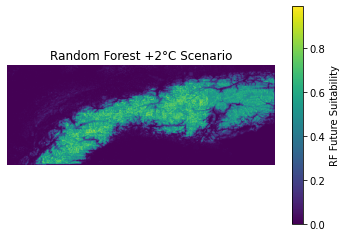

In [13]:
plt.imshow(prob_map_rf_future, cmap="viridis")
plt.colorbar(label="RF Future Suitability")
plt.title("Random Forest +2°C Scenario")
plt.axis("off")
plt.show()

### Habitat Loss

In [16]:
threshold = 0.5

baseline_bin = prob_map_rf > threshold
future_bin = prob_map_rf_future > threshold

baseline_area = baseline_bin.sum()
future_area = future_bin.sum()

print("Baseline area:", baseline_area)
print("Future area:", future_area)

Baseline area: 57330
Future area: 46083


In [17]:
print("Baseline mean:", prob_map_rf.mean())
print("Future mean:", prob_map_rf_future.mean())

baseline_high = (prob_map_rf > 0.7).sum()
future_high = (prob_map_rf_future > 0.7).sum()

print(baseline_high, future_high)

Baseline mean: 0.21838830308420443
Future mean: 0.18335017047785349
17440 11163
